# Project 1 — Exploratory Data Analysis on Retail Sales Data

**Oasis Infobyte | Data Analytics track**  
**Tools:** Python, pandas, NumPy, Matplotlib, Seaborn, Jupyter Notebook

## Business objective
Explore retail transactions to understand revenue trends, customer demographics, and product-category performance. Turn the analysis into evidence-based business recommendations.

## Dataset
This notebook uses the public 1,000-transaction Retail Sales Dataset. The available columns include transaction date, customer ID, gender, age, product category, quantity, unit price, and total amount.

**Data limitation:** this version records product *categories*, not individual product/SKU names. Therefore, the notebook ranks product categories; it cannot honestly produce a top-10 individual-product ranking without a product-name field. State this limitation in your submission rather than inventing product names.

In [1]:
# If you are using Google Colab and a library is missing, uncomment this line:
# !pip -q install pandas numpy matplotlib seaborn

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

OUTPUT_DIR = 'outputs'
os.makedirs(OUTPUT_DIR, exist_ok=True)
sns.set_theme(style='whitegrid')

In [2]:
# Load the public CSV. If the URL is unavailable, upload retail_sales_dataset.csv
# from the Kaggle dataset page: https://www.kaggle.com/datasets/mohammadtalib786/retail-sales-dataset
DATA_URL = 'https://raw.githubusercontent.com/Naseerahmadtaraki/RetailSotreDataset/main/retail_sales_dataset.csv'
try:
    raw = pd.read_csv(DATA_URL)
    print('Loaded dataset from public CSV source.')
except Exception as exc:
    print('Automatic download failed:', exc)
    try:
        from google.colab import files
        uploaded = files.upload()
        file_name = next(iter(uploaded))
    except ImportError:
        file_name = input('Enter the local path to retail_sales_dataset.csv: ').strip()
    raw = pd.read_csv(file_name)

print('Shape:', raw.shape)
display(raw.head())

Loaded dataset from public CSV source.
Shape: (1000, 9)


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [3]:
# Initial inspection
print('Column names:')
print(raw.columns.tolist())
print('\nData types:')
print(raw.dtypes)
print('\nMissing values by column:')
display(raw.isna().sum().rename('missing_count').to_frame())
print('\nExact duplicate rows:', raw.duplicated().sum())

Column names:
['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']

Data types:
Transaction ID       int64
Date                object
Customer ID         object
Gender              object
Age                  int64
Product Category    object
Quantity             int64
Price per Unit       int64
Total Amount         int64
dtype: object

Missing values by column:


,missing_count
Transaction ID,0
Date,0
Customer ID,0
Gender,0
Age,0
Product Category,0
Quantity,0
Price per Unit,0
Total Amount,0



Exact duplicate rows: 0


In [4]:
# Standardise column names and data types
# Keep a copy of the raw data for reproducibility.
df = raw.copy()
df.columns = [c.strip().lower().replace(' ', '_').replace('-', '_') for c in df.columns]

required = ['transaction_id', 'date', 'customer_id', 'gender', 'age',
            'product_category', 'quantity', 'price_per_unit', 'total_amount']
missing_required = [c for c in required if c not in df.columns]
if missing_required:
    raise ValueError(f'Required columns missing from dataset: {missing_required}')

df['date'] = pd.to_datetime(df['date'], errors='coerce')
for col in ['age', 'quantity', 'price_per_unit', 'total_amount']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Remove exact duplicates, then remove records with invalid transaction dates.
rows_before = len(df)
df = df.drop_duplicates().copy()
df = df.dropna(subset=['date']).copy()
print('Rows before:', rows_before, '| Rows after basic cleaning:', len(df))
print('Missing values after type conversion:')
display(df.isna().sum().to_frame('missing_count'))

Rows before: 1000 | Rows after basic cleaning: 1000
Missing values after type conversion:


,missing_count
transaction_id,0
date,0
customer_id,0
gender,0
age,0
product_category,0
quantity,0
price_per_unit,0
total_amount,0


In [5]:
# Add analysis features and validate transaction arithmetic
# Age groups are created for demographic analysis.
age_bins = [0, 18, 25, 35, 45, 55, 65, 100]
age_labels = ['Under 18', '18–24', '25–34', '35–44', '45–54', '55–64', '65+']
df['age_group'] = pd.cut(df['age'], bins=age_bins, labels=age_labels, right=False)
df['month'] = df['date'].dt.to_period('M').astype(str)
df['quarter'] = df['date'].dt.to_period('Q').astype(str)

# Compare stored total with quantity × unit price; do not silently overwrite source values.
df['calculated_amount'] = df['quantity'] * df['price_per_unit']
df['amount_difference'] = (df['total_amount'] - df['calculated_amount']).abs()
print('Transactions where stored total differs from quantity × unit price:',
      int((df['amount_difference'] > 0.01).sum()))

Transactions where stored total differs from quantity × unit price: 0


In [6]:
# Key performance indicators (KPIs)
total_revenue = df['total_amount'].sum()
total_transactions = df['transaction_id'].nunique()
unique_customers = df['customer_id'].nunique()
avg_transaction_value = df['total_amount'].mean()
total_units = df['quantity'].sum()

kpis = pd.DataFrame({
    'Metric': ['Total revenue', 'Unique transactions', 'Unique customers',
               'Average transaction value', 'Total units sold'],
    'Value': [total_revenue, total_transactions, unique_customers,
              avg_transaction_value, total_units]
})
display(kpis)

,Metric,Value
0,Total revenue,"456,000.00"
1,Unique transactions,"1,000.00"
2,Unique customers,"1,000.00"
3,Average transaction value,456.00
4,Total units sold,"2,514.00"


In [7]:
# Descriptive statistics for numerical columns
display(df[['age', 'quantity', 'price_per_unit', 'total_amount']].describe().T)
mode_values = df[['age', 'quantity', 'price_per_unit', 'total_amount']].mode().iloc[0]
display(mode_values.rename('mode').to_frame())

,count,mean,std,min,25%,50%,75%,max
age,"1,000.00",41.39,13.68,18.00,29.00,42.00,53.00,64.00
quantity,"1,000.00",2.51,1.13,1.00,1.00,3.00,4.00,4.00
price_per_unit,"1,000.00",179.89,189.68,25.00,30.00,50.00,300.00,500.00
total_amount,"1,000.00",456.00,560.00,25.00,60.00,135.00,900.00,"2,000.00"


,mode
age,43.00
quantity,4.00
price_per_unit,50.00
total_amount,50.00


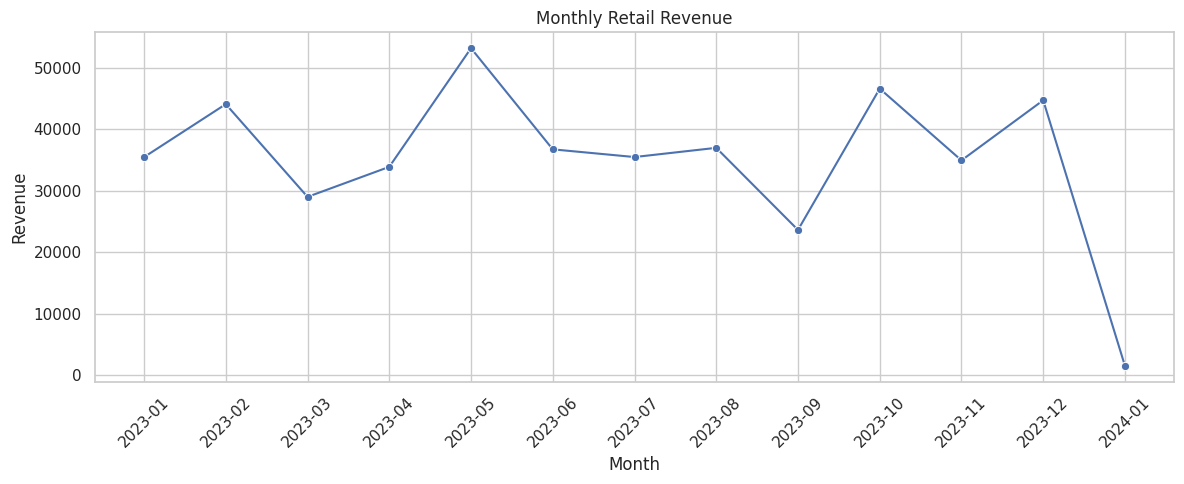

,quarter,total_amount
0,2023Q1,108500
1,2023Q2,123735
2,2023Q3,96045
3,2023Q4,126190
4,2024Q1,1530


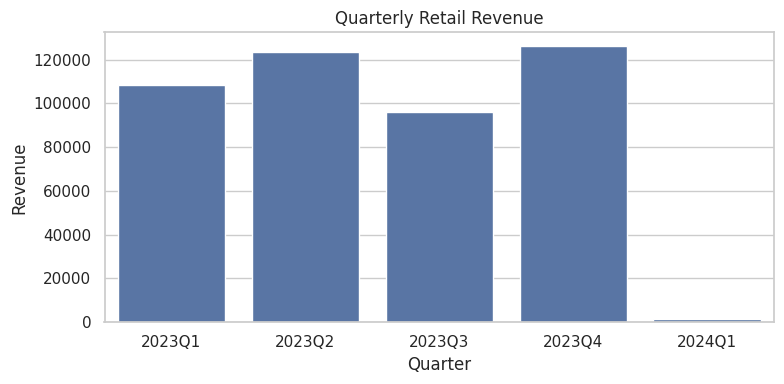

In [8]:
# Monthly and quarterly sales trends
monthly_sales = df.groupby('month', as_index=False)['total_amount'].sum()
quarterly_sales = df.groupby('quarter', as_index=False)['total_amount'].sum()

plt.figure(figsize=(12, 5))
sns.lineplot(data=monthly_sales, x='month', y='total_amount', marker='o')
plt.title('Monthly Retail Revenue')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/monthly_revenue.png', dpi=160)
plt.show()

display(quarterly_sales)
plt.figure(figsize=(8, 4))
sns.barplot(data=quarterly_sales, x='quarter', y='total_amount')
plt.title('Quarterly Retail Revenue')
plt.xlabel('Quarter')
plt.ylabel('Revenue')
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/quarterly_revenue.png', dpi=160)
plt.show()

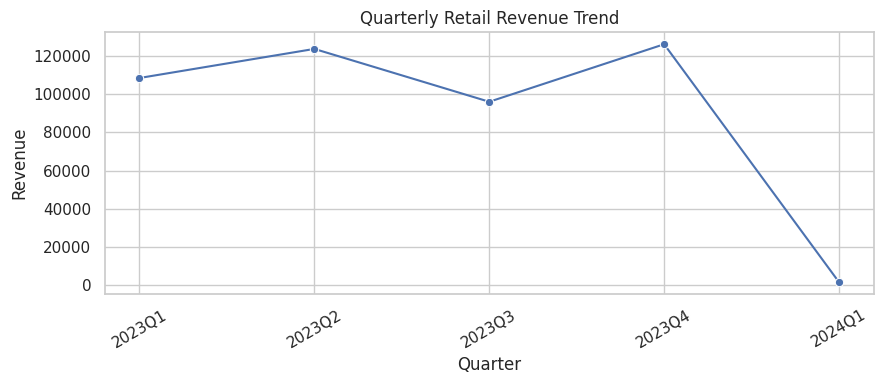

In [9]:
# Quarterly revenue trend as a line chart (required alongside the monthly line chart)
plt.figure(figsize=(9, 4))
sns.lineplot(data=quarterly_sales, x='quarter', y='total_amount', marker='o')
plt.title('Quarterly Retail Revenue Trend')
plt.xlabel('Quarter')
plt.ylabel('Revenue')
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/quarterly_revenue_trend.png', dpi=160)
plt.show()


**Observation — sales trends:** Monthly revenue peaked in **May 2023 (₹53,150)**. The highest quarter in the available data was **2023 Q4 (₹126,190)**. The 2024 Q1 period contains only a small partial-quarter total (₹1,530), so it should not be compared with complete quarters or used to claim a full-quarter decline.

,age_group,customers,transactions,revenue
0,Under 18,0,0,0
1,18–24,149,149,74650
2,25–34,203,203,97090
3,35–44,207,207,96835
4,45–54,225,225,97235
5,55–64,216,216,90190
6,65+,0,0,0


,gender,customers,transactions,revenue,average_order_value
0,Female,510,510,232840,456.55
1,Male,490,490,223160,455.43


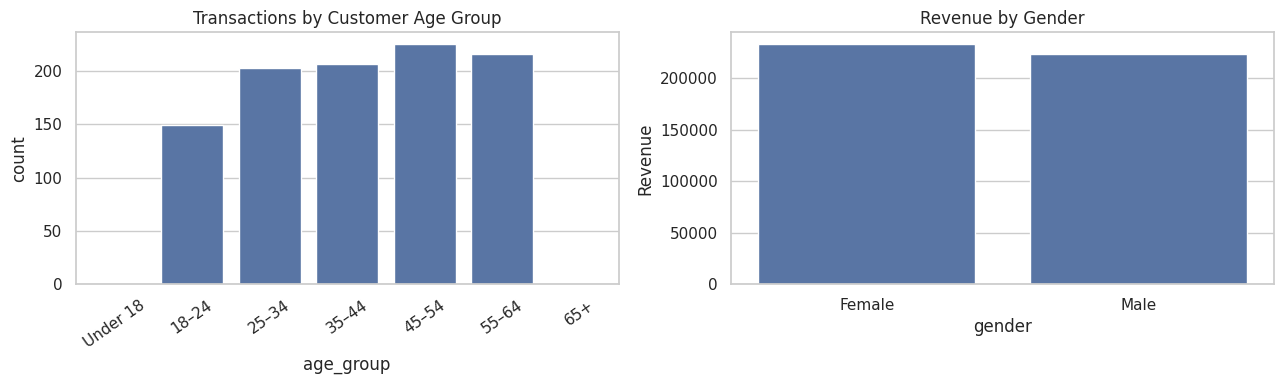

In [10]:
# Customer demographics: age group and gender
age_summary = df.groupby('age_group', observed=False).agg(
    customers=('customer_id', 'nunique'), transactions=('transaction_id', 'nunique'),
    revenue=('total_amount', 'sum')
).reset_index()
display(age_summary)

gender_summary = df.groupby('gender', dropna=False).agg(
    customers=('customer_id', 'nunique'), transactions=('transaction_id', 'nunique'),
    revenue=('total_amount', 'sum'), average_order_value=('total_amount', 'mean')
).reset_index()
display(gender_summary)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(data=df, x='age_group', order=age_labels, ax=axes[0])
axes[0].set_title('Transactions by Customer Age Group')
axes[0].tick_params(axis='x', rotation=35)
sns.barplot(data=gender_summary, x='gender', y='revenue', ax=axes[1])
axes[1].set_title('Revenue by Gender')
axes[1].set_ylabel('Revenue')
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/customer_demographics.png', dpi=160)
plt.show()

**Observation — customer demographics:** The 45–54 age group had the highest recorded revenue (₹97,235) and 225 transactions. Female transactions generated ₹232,840 (about 51.1% of revenue) versus ₹223,160 for male transactions (about 48.9%). Average transaction values were almost equal (₹456.55 and ₹455.43), so these differences are descriptive and do not show that gender caused spending differences.

,product_category,transactions,units_sold,revenue,average_transaction_value
0,Electronics,342,849,156905,458.79
1,Clothing,351,894,155580,443.25
2,Beauty,307,771,143515,467.48


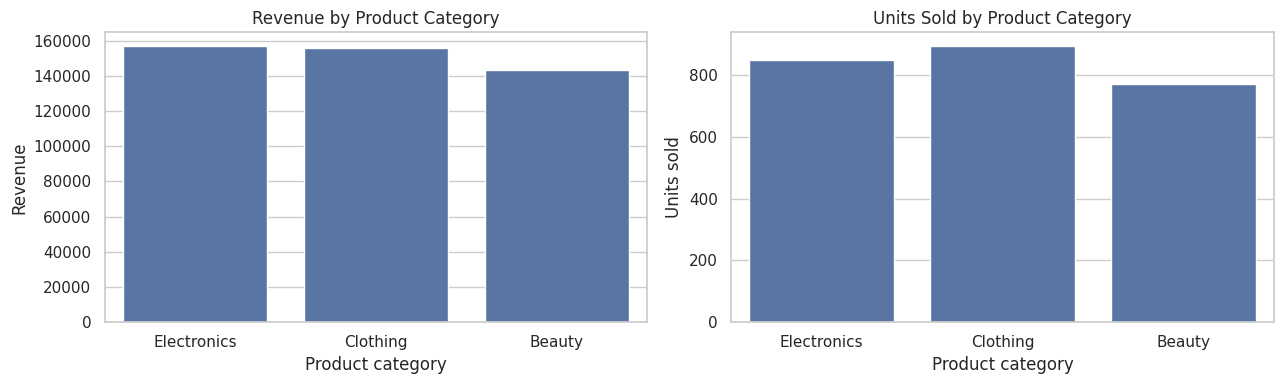

Data limitation: individual product/SKU names are not present in this dataset.
Therefore, top 10 individual products cannot be ranked; category-level performance is shown instead.


In [11]:
# Product-category analysis
category_summary = df.groupby('product_category').agg(
    transactions=('transaction_id', 'nunique'),
    units_sold=('quantity', 'sum'),
    revenue=('total_amount', 'sum'),
    average_transaction_value=('total_amount', 'mean')
).sort_values('revenue', ascending=False).reset_index()
display(category_summary)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.barplot(data=category_summary, x='product_category', y='revenue', ax=axes[0])
axes[0].set_title('Revenue by Product Category')
axes[0].set_xlabel('Product category')
axes[0].set_ylabel('Revenue')
sns.barplot(data=category_summary, x='product_category', y='units_sold', ax=axes[1])
axes[1].set_title('Units Sold by Product Category')
axes[1].set_xlabel('Product category')
axes[1].set_ylabel('Units sold')
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/category_performance.png', dpi=160)
plt.show()

print('Data limitation: individual product/SKU names are not present in this dataset.')
print('Therefore, top 10 individual products cannot be ranked; category-level performance is shown instead.')

**Observation — category performance:** Electronics generated the highest revenue (₹156,905), while Clothing sold the most units (894). Beauty had the highest average transaction value (₹467.48). This suggests inventory planning should consider both revenue and unit volume rather than using only one metric.

## Supplemental product-level analysis (separate dataset)

The demographic Retail Sales Dataset used above contains product categories, not SKU names. To meet the task's top-10 product analysis without inventing product names, this section uses a **separate Sample Superstore dataset** that contains `Product Name`, `Sales`, and `Quantity`. Keep the results separate: this supplemental dataset is a different fictional retailer and should not be merged with the demographic dataset or used to infer the same customers' behaviour.

Loaded supplemental Sample Superstore product-level dataset.


,product_name,total_quantity_sold,total_sales
1499,Staples,215,755.47
1493,Staple envelope,170,"1,686.81"
537,Easy-staple paper,150,"2,504.19"
1500,Staples in misc. colors,86,478.81
942,KI Adjustable-Height Table,74,"4,552.64"
1511,Storex Dura Pro Binders,71,278.59
259,Avery Non-Stick Binders,71,217.32
699,GBC Premium Transparent Covers with Diagonal L...,67,780.46
1450,"Situations Contoured Folding Chairs, 4/Set",64,"3,641.27"
1497,Staple-based wall hangings,62,422.29


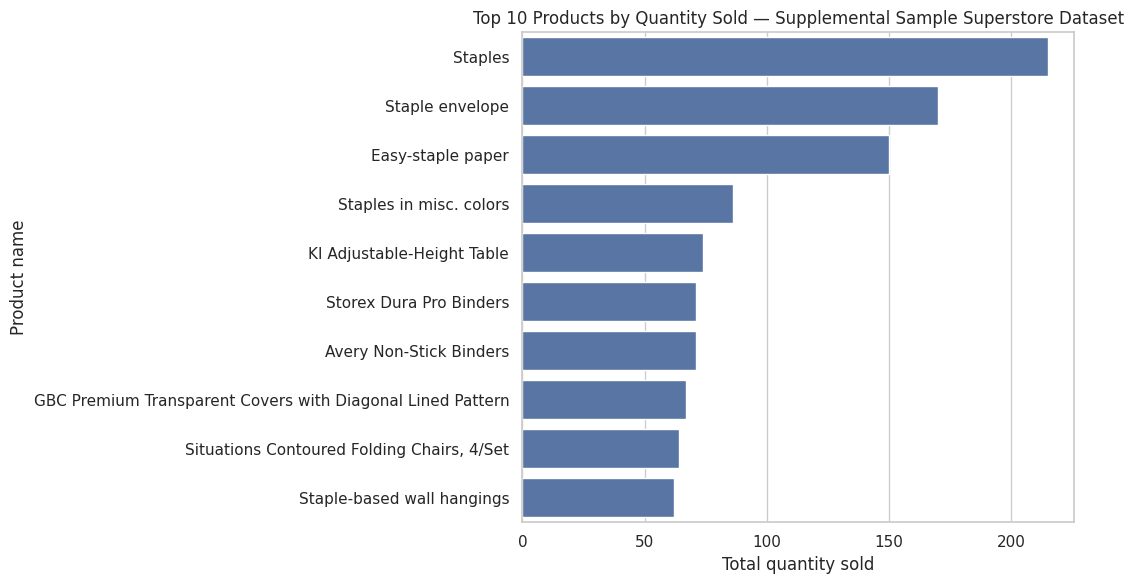

This top-10 ranking belongs only to the separate Sample Superstore dataset.


In [12]:
# Load a second public retail dataset that contains individual Product Name values.
# If this raw link is unavailable, download Sample - Superstore.csv and upload it below.
SUPERSTORE_URL = 'https://gist.githubusercontent.com/mateuszdorobek/98e7882f109bd3fb0763dc4ee1e8e260/raw/3bc8efee9878e91945e9d0a0fa4423f2247ca0ed/Sample%20-%20Superstore.csv'
try:
    product_df = pd.read_csv(SUPERSTORE_URL)
    print('Loaded supplemental Sample Superstore product-level dataset.')
except Exception as exc:
    print('Automatic download failed:', exc)
    try:
        from google.colab import files
        uploaded = files.upload()
        product_file = next(iter(uploaded))
    except ImportError:
        product_file = input('Enter the local path to Sample - Superstore.csv: ').strip()
    product_df = pd.read_csv(product_file)

product_df.columns = [c.strip().lower().replace(' ', '_') for c in product_df.columns]
needed = ['product_name', 'sales', 'quantity']
if any(c not in product_df.columns for c in needed):
    raise ValueError(f'Supplemental file must contain these columns: {needed}')
product_df['sales'] = pd.to_numeric(product_df['sales'], errors='coerce')
product_df['quantity'] = pd.to_numeric(product_df['quantity'], errors='coerce')
product_df = product_df.dropna(subset=['product_name', 'sales', 'quantity'])

top10_products = (product_df.groupby('product_name', as_index=False)
                  .agg(total_quantity_sold=('quantity', 'sum'), total_sales=('sales', 'sum'))
                  .sort_values(['total_quantity_sold', 'total_sales'], ascending=False)
                  .head(10))
display(top10_products)

plt.figure(figsize=(11, 6))
sns.barplot(data=top10_products, y='product_name', x='total_quantity_sold')
plt.title('Top 10 Products by Quantity Sold — Supplemental Sample Superstore Dataset')
plt.xlabel('Total quantity sold')
plt.ylabel('Product name')
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/top10_products_superstore.png', dpi=160)
plt.show()

top10_products.to_csv(f'{OUTPUT_DIR}/top10_products_superstore.csv', index=False)
print('This top-10 ranking belongs only to the separate Sample Superstore dataset.')

**Supplementary product-ranking note:** The top-10 product names above come from a separate Sample Superstore dataset, not the 1,000-transaction demographic dataset used for the main KPIs. Keep this ranking labelled as supplementary and do not combine its sales totals with the primary dataset's ₹456,000 revenue.

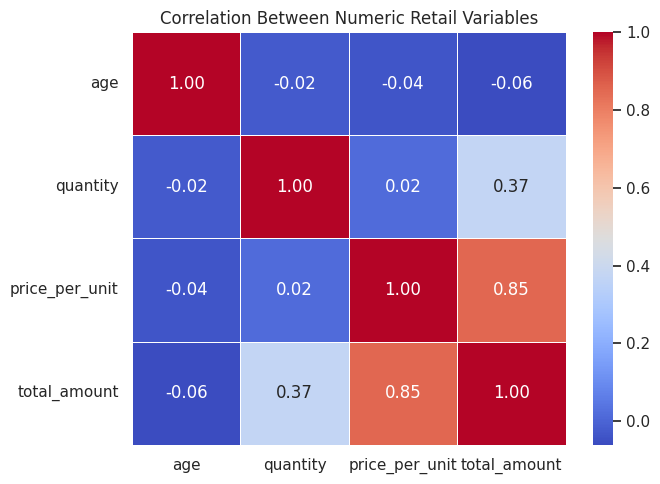

In [13]:
# Correlation heatmap for numeric fields
numeric = df[['age', 'quantity', 'price_per_unit', 'total_amount']]
correlation = numeric.corr(numeric_only=True)
plt.figure(figsize=(7, 5))
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f', linewidths=.5)
plt.title('Correlation Between Numeric Retail Variables')
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/correlation_heatmap.png', dpi=160)
plt.show()

**Observation — correlation heatmap:** Use the heatmap to inspect linear relationships among age, quantity, unit price and transaction amount. Correlation describes association only; it does not establish causation. Transaction amount is also mathematically related to quantity and unit price, so a positive relationship with those fields is expected.

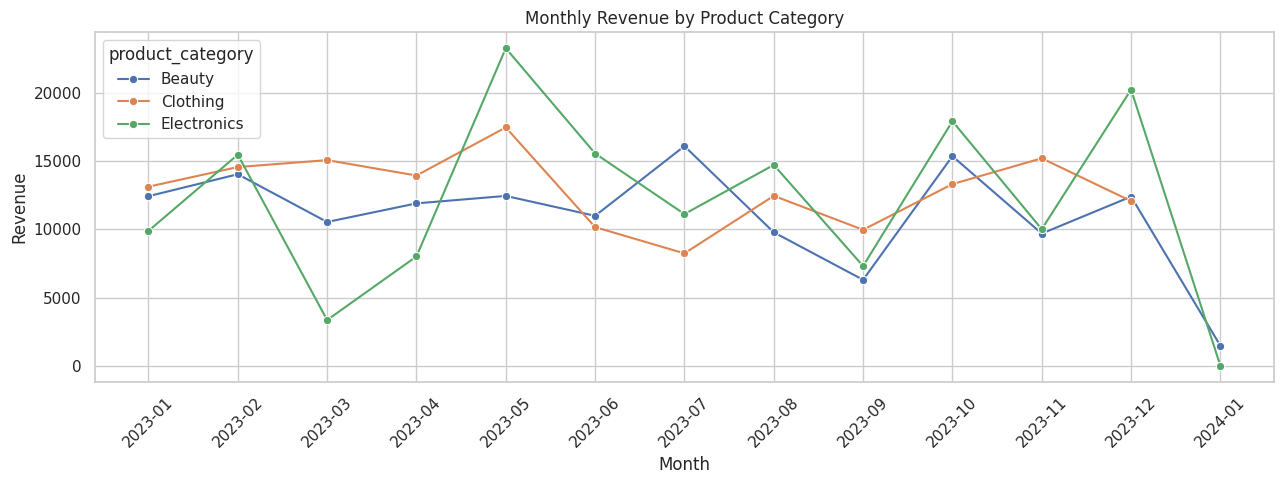

In [14]:
# Extra visualisation: monthly revenue by product category
monthly_category = df.groupby(['month', 'product_category'], as_index=False)['total_amount'].sum()
plt.figure(figsize=(13, 5))
sns.lineplot(data=monthly_category, x='month', y='total_amount', hue='product_category', marker='o')
plt.title('Monthly Revenue by Product Category')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/monthly_revenue_by_category.png', dpi=160)
plt.show()

**Observation — monthly category pattern:** This chart compares how each product category contributes to monthly revenue. Use it to identify months that may warrant further review; the dataset covers a limited period, so recurring seasonality should not be claimed without additional years of data.

In [15]:
# Generate evidence-based findings. Review these values and use them in the written conclusion.
top_category = category_summary.iloc[0]
top_gender = gender_summary.sort_values('revenue', ascending=False).iloc[0]
peak_month = monthly_sales.sort_values('total_amount', ascending=False).iloc[0]
print(f"1. Highest-revenue category: {top_category['product_category']} "
      f"(revenue {top_category['revenue']:,.2f}).")
print(f"2. Gender group with the highest recorded revenue: {top_gender['gender']} "
      f"(revenue {top_gender['revenue']:,.2f}).")
print(f"3. Highest-revenue month: {peak_month['month']} "
      f"(revenue {peak_month['total_amount']:,.2f}).")
print('Recommendation prompts:')
print('- Align inventory with category demand and seasonal/monthly peaks.')
print('- Test targeted campaigns by customer segment; validate results with further data.')
print('- Collect SKU-level product names in future systems to support top-product analysis.')

1. Highest-revenue category: Electronics (revenue 156,905.00).
2. Gender group with the highest recorded revenue: Female (revenue 232,840.00).
3. Highest-revenue month: 2023-05 (revenue 53,150.00).
Recommendation prompts:
- Align inventory with category demand and seasonal/monthly peaks.
- Test targeted campaigns by customer segment; validate results with further data.
- Collect SKU-level product names in future systems to support top-product analysis.


**Business interpretation:** Treat the output above as descriptive evidence from this dataset. Recommendations should be tested against newer and more complete transaction data before being used as operational policy.

In [16]:
# Export the cleaned analysis dataset and key summary tables
clean_export = df.drop(columns=['calculated_amount', 'amount_difference'], errors='ignore')
clean_export.to_csv(f'{OUTPUT_DIR}/retail_sales_cleaned.csv', index=False)
category_summary.to_csv(f'{OUTPUT_DIR}/revenue_by_category.csv', index=False)
monthly_sales.to_csv(f'{OUTPUT_DIR}/monthly_revenue.csv', index=False)
print('Saved outputs in:', OUTPUT_DIR)

Saved outputs in: outputs


## Final report — verified findings

### 1. Dataset and data quality
- The primary Retail Sales dataset contains **1,000 transactions** and **9 original columns**.
- The dataset contains **1,000 unique customer IDs** and **1,000 unique transaction IDs**. In this file, each customer appears once, so repeat-purchase or customer-lifetime-value analysis is not supported.
- The initial data check found **0 missing values** and **0 exact duplicate rows**.
- The date field was converted to a datetime type. After type conversion and basic cleaning, all **1,000 rows** remained.
- The stored transaction amount matched `quantity × price_per_unit` for all **1,000 records** (0 mismatches).

### 2. Overall sales performance
- **Total revenue:** 456,000 currency units.
- **Number of transactions:** 1,000.
- **Average transaction value:** 456 currency units.
- **Total units sold:** 2,514.
- Revenue was highest in **May 2023: 53,150**.
- The highest quarter in the available summary was **2023 Q4: 126,190**. The 2024 Q1 total is only 1,530 and appears to represent an incomplete quarter, so it should not be compared with full quarters as though coverage were equal.

### 3. Customer demographics
- Female transactions generated **232,840** in revenue (about **51.1%** of the total), while male transactions generated **223,160** (about **48.9%**).
- Average transaction values were very close: **456.55** for female transactions and **455.43** for male transactions. The difference is small and does not establish that gender caused higher spending.
- The **45–54** age group had the largest number of transactions (**225**) and the highest age-group revenue (**97,235**). Revenue across the 25–34, 35–44, and 45–54 groups was similar, so the pattern should be treated as descriptive rather than proof of a strong age preference.

### 4. Product-category performance
| Product category | Transactions | Units sold | Revenue |
|---|---:|---:|---:|
| Electronics | 342 | 849 | 156,905 |
| Clothing | 351 | 894 | 155,580 |
| Beauty | 307 | 771 | 143,515 |

- **Electronics** generated the highest category revenue (**156,905**).
- **Clothing** sold the most units (**894**).
- Beauty had the highest average transaction value (**467.48**).

### 5. Business recommendations
1. **Plan inventory by both revenue and unit volume.** Prioritise availability for Electronics because it generated the most revenue, while monitoring Clothing stock closely because it had the highest unit volume.
2. **Review the May 2023 and Q4 2023 peaks.** Compare promotions, stock levels and operating conditions around these periods before setting future seasonal inventory or marketing plans. More complete years of data would be needed to confirm a recurring seasonal pattern.
3. **Test customer campaigns using measured results.** The gender revenue difference is modest, and age-group revenues are fairly close. Run small, measurable campaigns by customer group and compare conversion and average transaction value rather than assuming demographic causation.
4. **Capture product/SKU-level information in future transaction records.** The primary dataset has `Product Category` but no individual product-name field, so it cannot support a top-10 individual-product ranking.

### 6. Important dataset limitation and supplementary product list
The primary 1,000-row dataset supports category-level analysis, not individual product/SKU ranking. The notebook's optional top-10 product table is generated from a **separate Sample Superstore dataset**. Its product names and sales figures must be labelled as a separate supplementary example and must **not** be combined with the 456,000 revenue total or described as products sold in the primary Retail Sales dataset.

### Conclusion
The analysis of 1,000 retail transactions recorded total revenue of 456,000 and an average transaction value of 456. Electronics led category revenue, Clothing led units sold, May 2023 was the strongest month, and Q4 2023 was the strongest quarter in the available summary. The results suggest practical opportunities in inventory planning, seasonal review and evidence-based campaign testing. Conclusions are limited by the dataset's short time coverage, one transaction per customer ID, and lack of individual product names.

